# Tool Calls vs. Accuracy Analysis
**Question:** Does the number of tools called affect whether the model gets the answer right?

**Correctness definition:** an item is correct if *either* the GPT-5.4 judge **or** the Claude Opus 4.6 judge marks it as correct.

In [ ]:
# Run from the repo root so the root-relative data paths below resolve
import os
from pathlib import Path
os.chdir(next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "sec3_occludebench").is_dir()))

In [17]:
import json
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from scipy import stats
import warnings
warnings.filterwarnings('ignore')

plt.rcParams.update({'font.family': 'Arial', 'font.size': 45})


In [18]:
with open('data/eval_results_tool_use_thinking_v2/gpt-5.4_judged_results.json') as f:
    gpt_data = json.load(f)
with open('data/eval_results_tool_use_thinking_v2/claude-opus-4-6_judged_results.json') as f:
    claude_data = json.load(f)

print(f'GPT-5.4 records:        {len(gpt_data)}')
print(f'Claude Opus 4.6 records: {len(claude_data)}')
print('\nSample item (gpt):')
sample = gpt_data[0]
print(f'  id: {sample["id"]}')
print(f'  occluded_correct: {sample["occluded_correct"]}')
print(f'  tool_calls count: {len(sample["tool_calls"])}')

GPT-5.4 records:        197
Claude Opus 4.6 records: 197

Sample item (gpt):
  id: 2
  occluded_correct: {'gpt-5.4': True, 'claude-opus-4-6': True}
  tool_calls count: 5


In [19]:
def extract(data):
    """Return (n_tools, is_correct) arrays. Correct = either judge says True."""
    n_tools, correct = [], []
    for item in data:
        oc = item['occluded_correct']
        is_correct = oc.get('gpt-5.4', False) or oc.get('claude-opus-4-6', False)
        n_tools.append(len(item['tool_calls']))
        correct.append(int(is_correct))
    return np.array(n_tools), np.array(correct)

gpt_n,    gpt_c    = extract(gpt_data)
claude_n, claude_c = extract(claude_data)

for name, n, c in [('GPT-5.4', gpt_n, gpt_c), ('Claude Opus 4.6', claude_n, claude_c)]:
    print(f'{name}: N={len(n)}, correct={c.sum()} ({100*c.mean():.1f}%)')
    import collections
    print(f'  tool call distribution: {dict(sorted(collections.Counter(n).items()))}')

GPT-5.4: N=197, correct=92 (46.7%)
  tool call distribution: {2: 4, 3: 2, 4: 12, 5: 179}
Claude Opus 4.6: N=197, correct=102 (51.8%)
  tool call distribution: {1: 2, 2: 34, 3: 56, 4: 55, 5: 50}


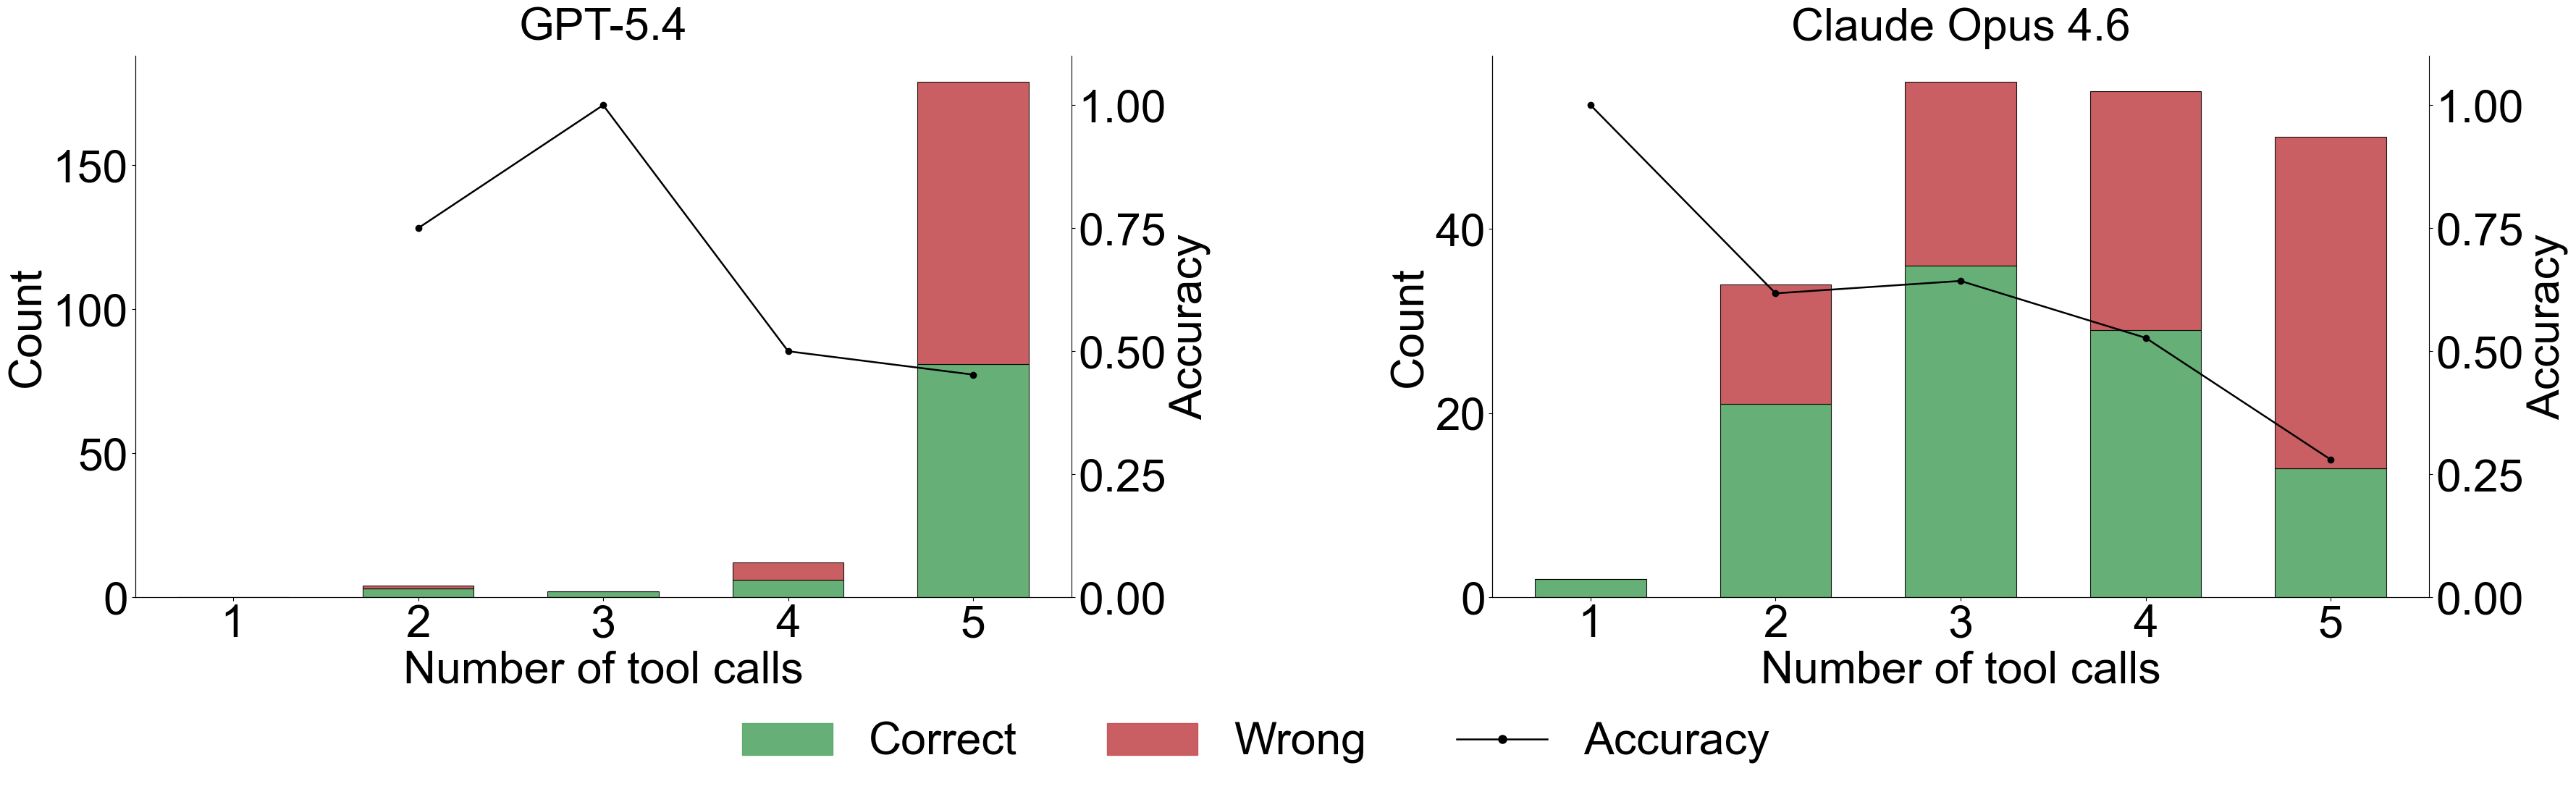

In [20]:
import matplotlib.patches as mpatches
import matplotlib.lines as mlines

color_c, color_w = '#55A868', '#C44E52'

datasets = [
    (gpt_n,    gpt_c,    'GPT-5.4'),
    (claude_n, claude_c, 'Claude Opus 4.6'),
]

fig, axes = plt.subplots(1, 2, figsize=(36, 11))

for ax, (n_tools, correct, model_name) in zip(axes, datasets):
    bin_centers = np.arange(1, n_tools.max() + 1)
    for b in bin_centers:
        mask = n_tools == b
        n_c = correct[mask].sum()
        n_w = mask.sum() - n_c
        ax.bar(b, n_c, color=color_c, alpha=0.9, width=0.6, edgecolor='black', linewidth=0.8)
        ax.bar(b, n_w, bottom=n_c, color=color_w, alpha=0.9, width=0.6, edgecolor='black', linewidth=0.8)
    ax.set_xlabel('Number of tool calls', fontsize=45)
    ax.set_ylabel('Count', fontsize=45)
    ax.set_title(f'{model_name}', fontsize=45, pad=16)
    ax.set_xticks(bin_centers)
    ax.tick_params(labelsize=45)
    ax.spines[['top', 'right']].set_visible(False)

    ax2 = ax.twinx()
    acc_xs = [b for b in bin_centers if (n_tools == b).sum() > 0]
    acc_vals = [correct[n_tools == b].mean() for b in acc_xs]
    ax2.plot(acc_xs, acc_vals, 'o-', color='black', lw=1.8, ms=6, zorder=5)
    ax2.set_ylim(0, 1.1)
    ax2.set_ylabel('Accuracy', fontsize=45)
    ax2.tick_params(labelsize=45)
    ax2.spines[['top']].set_visible(False)

legend_handles = [
    mpatches.Patch(color=color_c, alpha=0.9, label='Correct'),
    mpatches.Patch(color=color_w, alpha=0.9, label='Wrong'),
    mlines.Line2D([], [], color='black', marker='o', lw=1.8, ms=8, label='Accuracy'),
]
fig.legend(handles=legend_handles, loc='lower center', ncol=3, fontsize=45,
           bbox_to_anchor=(0.5, -0.04), frameon=False)

fig.subplots_adjust(left=0.07, right=0.95, bottom=0.22, top=0.90, wspace=0.45)
plt.savefig('data/figures/tool_call_analysis_combined.pdf', bbox_inches='tight')
plt.show()

In [21]:
def effect_size_label(val, thresholds=(0.1, 0.3, 0.5)):
    a = abs(val)
    if a < thresholds[0]: return "negligible"
    if a < thresholds[1]: return "small"
    if a < thresholds[2]: return "medium"
    return "large"

def hypothesis_tests(n_tools, correct, model_name):
    correct_tools = n_tools[correct == 1]
    wrong_tools   = n_tools[correct == 0]
    n1, n2 = len(correct_tools), len(wrong_tools)

    print(f'=== {model_name} ===')
    print(f'N = {len(n_tools)}  |  correct: {correct.sum()} ({100*correct.mean():.1f}%)  |  '
          f'incorrect: {(1-correct).sum()} ({100*(1-correct).mean():.1f}%)')
    print(f'Mean tool calls — correct: {correct_tools.mean():.3f} ± {correct_tools.std():.3f}  |  '
          f'incorrect: {wrong_tools.mean():.3f} ± {wrong_tools.std():.3f}')
    print()

    # H₁: more tools → higher accuracy (one-sided, all tests)

    # --- Mann-Whitney U ---
    # Effect size: rank-biserial correlation r_rb = 1 - 2U/(n1*n2), range [-1, 1]
    u_stat, p_mw = stats.mannwhitneyu(correct_tools, wrong_tools, alternative='greater')
    r_rb = 1 - (2 * u_stat) / (n1 * n2)
    print(f'Mann-Whitney U test  (H₁: correct group uses more tools)')
    print(f'  U = {u_stat:.1f},  p = {p_mw:.4f}  → {"REJECT" if p_mw < 0.05 else "fail to reject"} H₀ at α=0.05')
    print(f'  Effect size: rank-biserial r = {r_rb:+.4f}  ({effect_size_label(r_rb)})')
    print()

    # --- Point-biserial ---
    # r_pb is itself an effect size; also report Cohen's d = 2r / sqrt(1 - r^2)
    r_pb, p_two = stats.pointbiserialr(correct, n_tools)
    p_rpb = p_two / 2 if r_pb > 0 else 1 - p_two / 2
    cohens_d_from_r = 2 * r_pb / np.sqrt(1 - r_pb**2)
    print(f'Point-biserial correlation  (H₁: r > 0, more tools → correct)')
    print(f'  r = {r_pb:+.4f},  p (one-sided) = {p_rpb:.4f}  → {"REJECT" if p_rpb < 0.05 else "fail to reject"} H₀ at α=0.05')
    print(f'  Effect size: r = {r_pb:+.4f}  ({effect_size_label(r_pb)})  |  Cohen\'s d = {cohens_d_from_r:+.4f}')
    print()

    # --- Permutation test ---
    # Effect size: Cohen's d = Δmean / pooled SD
    obs_diff = correct_tools.mean() - wrong_tools.mean()
    pooled_sd = np.sqrt(((n1 - 1) * correct_tools.std()**2 + (n2 - 1) * wrong_tools.std()**2) / (n1 + n2 - 2))
    cohens_d = obs_diff / pooled_sd if pooled_sd > 0 else 0.0
    rng = np.random.default_rng(42)
    perm_diffs = np.array([
        rng.permutation(n_tools)[correct == 1].mean() - rng.permutation(n_tools)[correct == 0].mean()
        for _ in range(10_000)
    ])
    p_perm = np.mean(perm_diffs >= obs_diff)
    print(f'Permutation test on mean difference  (H₁: Δmean > 0, 10 000 permutations)')
    print(f'  Observed Δmean = {obs_diff:+.4f},  p (one-sided) = {p_perm:.4f}  → {"REJECT" if p_perm < 0.05 else "fail to reject"} H₀ at α=0.05')
    print(f'  Effect size: Cohen\'s d = {cohens_d:+.4f}  ({effect_size_label(cohens_d, thresholds=(0.2, 0.5, 0.8))})')
    print()
    if obs_diff < 0:
        print(f'  ⚠ Note: observed effect is in the OPPOSITE direction (fewer tools → higher accuracy).')

hypothesis_tests(gpt_n, gpt_c, 'GPT-5.4')

=== GPT-5.4 ===
N = 197  |  correct: 92 (46.7%)  |  incorrect: 105 (53.3%)
Mean tool calls — correct: 4.793 ± 0.635  |  incorrect: 4.914 ± 0.368

Mann-Whitney U test  (H₁: correct group uses more tools)
  U = 4563.5,  p = 0.9097  → fail to reject H₀ at α=0.05
  Effect size: rank-biserial r = +0.0552  (negligible)

Point-biserial correlation  (H₁: r > 0, more tools → correct)
  r = -0.1173,  p (one-sided) = 0.9496  → fail to reject H₀ at α=0.05
  Effect size: r = -0.1173  (small)  |  Cohen's d = -0.2362

Permutation test on mean difference  (H₁: Δmean > 0, 10 000 permutations)
  Observed Δmean = -0.1208,  p (one-sided) = 0.9911  → fail to reject H₀ at α=0.05
  Effect size: Cohen's d = -0.2368  (small)

  ⚠ Note: observed effect is in the OPPOSITE direction (fewer tools → higher accuracy).


In [22]:
hypothesis_tests(claude_n, claude_c, 'Claude Opus 4.6')

=== Claude Opus 4.6 ===
N = 197  |  correct: 102 (51.8%)  |  incorrect: 95 (48.2%)
Mean tool calls — correct: 3.314 ± 1.010  |  incorrect: 3.895 ± 1.061

Mann-Whitney U test  (H₁: correct group uses more tools)
  U = 3376.5,  p = 0.9999  → fail to reject H₀ at α=0.05
  Effect size: rank-biserial r = +0.3031  (medium)

Point-biserial correlation  (H₁: r > 0, more tools → correct)
  r = -0.2702,  p (one-sided) = 0.9999  → fail to reject H₀ at α=0.05
  Effect size: r = -0.2702  (small)  |  Cohen's d = -0.5612

Permutation test on mean difference  (H₁: Δmean > 0, 10 000 permutations)
  Observed Δmean = -0.5810,  p (one-sided) = 1.0000  → fail to reject H₀ at α=0.05
  Effect size: Cohen's d = -0.5615  (medium)

  ⚠ Note: observed effect is in the OPPOSITE direction (fewer tools → higher accuracy).


## Tool Usage Frequency

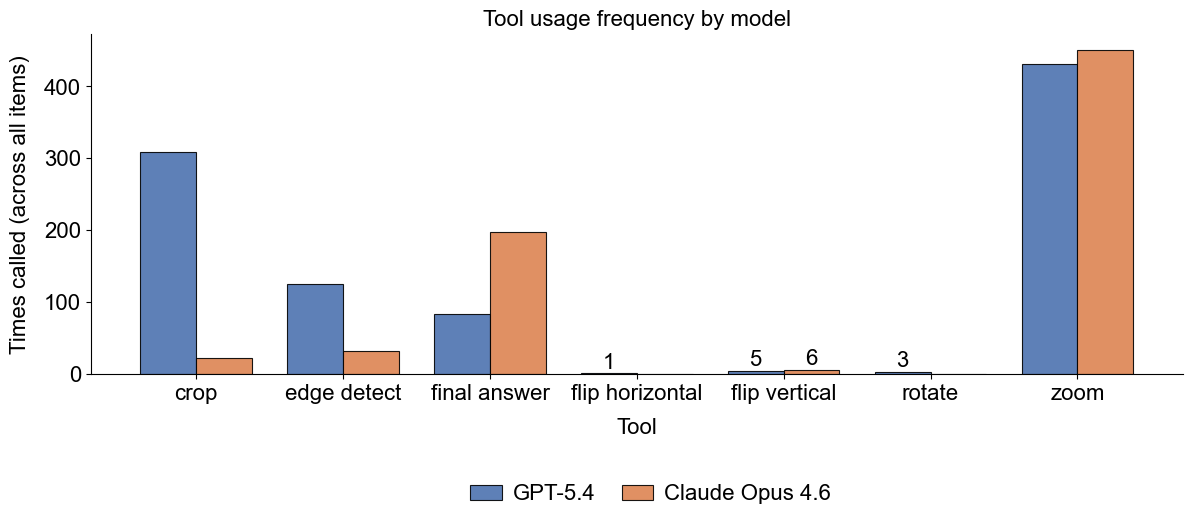

Raw counts:
Tool                 GPT-5.4    Claude
  crop                   308        23
  edge_detect            125        32
  final_answer            84       197
  flip_horizontal          1         0
  flip_vertical            5         6
  rotate                   3         0
  zoom                   431       450


In [23]:
import collections

ALL_TOOLS = ['zoom', 'crop', 'rotate', 'edge_detect', 'flip_horizontal', 'flip_vertical', 'final_answer']

def tool_counts(data):
    counts = collections.Counter()
    for item in data:
        for tc in item['tool_calls']:
            counts[tc['tool']] += 1
    return counts

gpt_counts    = tool_counts(gpt_data)
claude_counts = tool_counts(claude_data)

all_seen = sorted(set(ALL_TOOLS) | set(gpt_counts) | set(claude_counts))

gpt_vals    = [gpt_counts[t]    for t in all_seen]
claude_vals = [claude_counts[t] for t in all_seen]

x = np.arange(len(all_seen))
width = 0.38

fig, ax = plt.subplots(figsize=(14, 5))
bars1 = ax.bar(x - width/2, gpt_vals,    width, label='GPT-5.4',        color='#4C72B0', alpha=0.9, edgecolor='black', linewidth=0.8)
bars2 = ax.bar(x + width/2, claude_vals, width, label='Claude Opus 4.6', color='#DD8452', alpha=0.9, edgecolor='black', linewidth=0.8)

ax.set_xlabel('Tool', fontsize=16, labelpad=10)
ax.set_ylabel('Times called (across all items)', fontsize=16, labelpad=10)
ax.set_title('Tool usage frequency by model', fontsize=16)
ax.set_xticks(x)
ax.set_xticklabels([t.replace('_', ' ') for t in all_seen], rotation=0, ha='center', fontsize=16)
ax.tick_params(axis='y', labelsize=16)
ax.spines[['top', 'right']].set_visible(False)

for bar in bars1:
    h = bar.get_height()
    if 0 < h < 10:
        ax.text(bar.get_x() + bar.get_width()/2, h + 1, str(int(h)),
                ha='center', va='bottom', fontsize=16)
for bar in bars2:
    h = bar.get_height()
    if 0 < h < 10:
        ax.text(bar.get_x() + bar.get_width()/2, h + 1, str(int(h)),
                ha='center', va='bottom', fontsize=16)

fig.legend(loc='lower center', ncol=2, bbox_to_anchor=(0.5, -0.08),
           frameon=False, fontsize=16, columnspacing=1.2,
           handlelength=1.4, handletextpad=0.5)

fig.subplots_adjust(left=0.10, right=0.88, bottom=0.22, top=0.90)
plt.savefig('data/figures/tool_call_analysis_tool_usage_frequency_by_model.pdf', bbox_inches='tight')
plt.show()

print('Raw counts:')
print(f"{'Tool':<18}  {'GPT-5.4':>8}  {'Claude':>8}")
for t in all_seen:
    print(f"  {t:<16}  {gpt_counts[t]:>8}  {claude_counts[t]:>8}")
